In [1]:

# %pip install pandas numpy scikit-learn statsmodels matplotlib seaborn

import io
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)
from IPython.display import display

warnings.filterwarnings("ignore")
RANDOM_STATE = 15
np.random.seed(RANDOM_STATE)

OUTPUT_DIR = Path("adult_income_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
print("Random state:", RANDOM_STATE)
print("Output folder:", OUTPUT_DIR.resolve())

Random state: 15
Output folder: /content/adult_income_outputs


In [2]:
COLUMNS = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week", "native_country",
    "income"
]

TRAIN_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
TEST_URL  = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test"

adult_train = pd.read_csv(
    TRAIN_URL, names=COLUMNS, sep=",", skipinitialspace=True,
    na_values="?", comment="|"
)
adult_test = pd.read_csv(
    TEST_URL, names=COLUMNS, sep=",", skipinitialspace=True,
    na_values="?", comment="|", skiprows=1
)

df = pd.concat([adult_train, adult_test], ignore_index=True)
df["income"] = (
    df["income"].astype(str).str.strip().str.replace(".", "", regex=False)
)
df = df[df["income"].isin([">50K", "<=50K"])].copy()
df["income_binary"] = (df["income"] == ">50K").astype(int)

print("Combined dataset shape:", df.shape)
print("\nTarget counts:")
print(df["income"].value_counts(dropna=False))
print("\nMissing values before preprocessing:")
print(df.isna().sum().sort_values(ascending=False))
display(df.head())


Combined dataset shape: (48842, 16)

Target counts:
income
<=50K    37155
>50K     11687
Name: count, dtype: int64

Missing values before preprocessing:
occupation        2809
workclass         2799
native_country     857
fnlwgt               0
education            0
education_num        0
marital_status       0
age                  0
relationship         0
race                 0
capital_gain         0
sex                  0
capital_loss         0
hours_per_week       0
income               0
income_binary        0
dtype: int64


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,income_binary
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,0


Train rows: 34,189 (70.0%)
Test rows:  14,653 (30.0%)
Encoded feature count: 100
Missing values after preprocessing (encoded train): 0


,count,mean,std,min,25%,50%,75%,max
age,48842.0,38.643585,13.710510,17.0,28.0,37.0,48.0,90.0
fnlwgt,48842.0,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education_num,48842.0,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
capital_gain,48842.0,1079.067626,7452.019058,0.0,0.0,0.0,0.0,99999.0
capital_loss,48842.0,87.502314,403.004552,0.0,0.0,0.0,0.0,4356.0
hours_per_week,48842.0,40.422382,12.391444,1.0,40.0,40.0,45.0,99.0


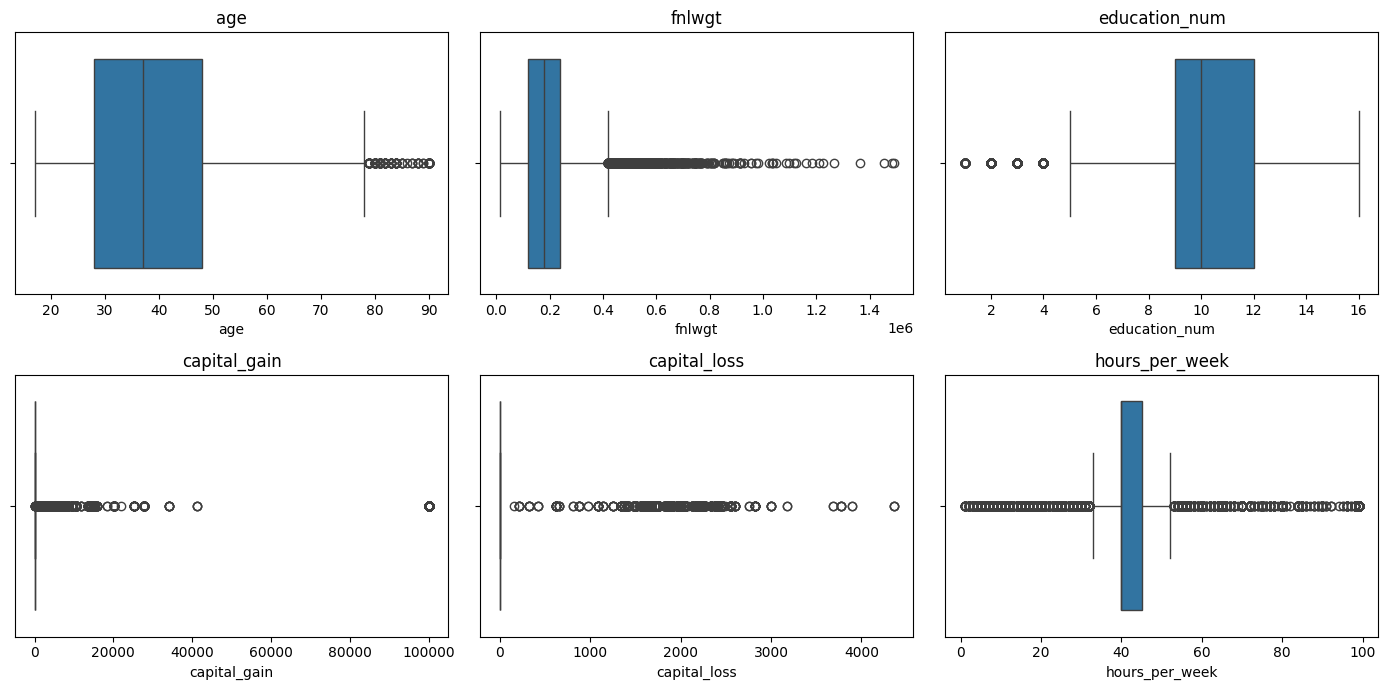

In [3]:
TARGET = "income_binary"
SENSITIVE = "sex"  # Primary fairness comparison: Male vs Female
NUMERIC = [
    "age", "fnlwgt", "education_num", "capital_gain",
    "capital_loss", "hours_per_week"
]
CATEGORICAL = [
    "workclass", "education", "marital_status", "occupation",
    "relationship", "race", "sex", "native_country"
]
FEATURES = NUMERIC + CATEGORICAL

X = df[FEATURES].copy()
y = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("onehot", __import__("sklearn").preprocessing.OneHotEncoder(
        handle_unknown="ignore", drop="first", sparse_output=False
    ))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, NUMERIC),
    ("cat", categorical_pipe, CATEGORICAL)
], verbose_feature_names_out=False)

X_train_arr = preprocessor.fit_transform(X_train)
X_test_arr = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

X_train_enc = pd.DataFrame(X_train_arr, columns=feature_names, index=X_train.index)
X_test_enc = pd.DataFrame(X_test_arr, columns=feature_names, index=X_test.index)

print(f"Train rows: {len(X_train):,} ({len(X_train)/len(df):.1%})")
print(f"Test rows:  {len(X_test):,} ({len(X_test)/len(df):.1%})")
print("Encoded feature count:", len(feature_names))
print("Missing values after preprocessing (encoded train):", int(X_train_enc.isna().sum().sum()))

# Numeric summary and optional boxplots for report documentation
display(df[NUMERIC].describe().T)
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for col, ax in zip(NUMERIC, axes.flat):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "numeric_boxplots.png", dpi=160, bbox_inches="tight")
plt.show()


In [4]:
ols = LinearRegression()
ols.fit(X_train_enc, y_train)
ols_pred = ols.predict(X_test_enc)
ols_cutoff = float(np.median(ols_pred))
ols_class = (ols_pred >= ols_cutoff).astype(int)

logit = LogisticRegression(max_iter=3000, solver="lbfgs", random_state=RANDOM_STATE)
logit.fit(X_train_enc, y_train)
logit_prob = logit.predict_proba(X_test_enc)[:, 1]
logit_class = (logit_prob >= 0.50).astype(int)

# Rows = OLS decision (0, 1); columns = logistic decision (0, 1)
agreement_cm = confusion_matrix(ols_class, logit_class, labels=[0, 1])
mismatch = ols_class != logit_class
mismatch_n = int(mismatch.sum())
mismatch_pct = 100 * mismatch.mean()

print(f"Median OLS predicted value (test set): {ols_cutoff:.6f}")
print(f"Logistic classification threshold: 0.500000")
print(f"Mismatched individuals: {mismatch_n:,} / {len(y_test):,} = {mismatch_pct:.2f}%")
print("Confusion matrix: rows=OLS class [low, high], columns=logistic class [low, high]")
display(pd.DataFrame(
    agreement_cm,
    index=["OLS low risk (0)", "OLS high risk (1)"],
    columns=["Logistic low risk (0)", "Logistic high risk (1)"]
))
print("\nSeparate predictive performance against the actual target (for context):")
print("OLS threshold accuracy:", round(accuracy_score(y_test, ols_class), 4))
print("Logistic accuracy:", round(accuracy_score(y_test, logit_class), 4))
print("Logistic ROC-AUC:", round(roc_auc_score(y_test, logit_prob), 4))

part1 = pd.DataFrame({
    "actual_income_binary": y_test.to_numpy(),
    "ols_prediction": ols_pred,
    "ols_class_median_threshold": ols_class,
    "logistic_probability": logit_prob,
    "logistic_class_0.5_threshold": logit_class,
    "mismatch": mismatch
}, index=y_test.index)
part1.to_csv(OUTPUT_DIR / "part1_test_predictions.csv", index=True)


Median OLS predicted value (test set): 0.228125
Logistic classification threshold: 0.500000
Mismatched individuals: 4,514 / 14,653 = 30.81%
Confusion matrix: rows=OLS class [low, high], columns=logistic class [low, high]


,Logistic low risk (0),Logistic high risk (1)
OLS low risk (0),7308,18
OLS high risk (1),4496,2831



Separate predictive performance against the actual target (for context):
OLS threshold accuracy: 0.7088
Logistic accuracy: 0.8497
Logistic ROC-AUC: 0.9027


In [5]:
EXPL_NUMERIC = ["age", "education_num", "hours_per_week", "capital_gain", "capital_loss"]
EXPL_CATEGORICAL = ["sex"]
EXPL_FEATURES = EXPL_NUMERIC + EXPL_CATEGORICAL

train_raw = X_train[EXPL_FEATURES].copy()
train_y = y_train.copy()
test_raw = X_test[EXPL_FEATURES].copy()
test_y = y_test.copy()

EXPL_MEANS = train_raw[EXPL_NUMERIC].apply(pd.to_numeric, errors="coerce").mean()
EXPL_STDS = train_raw[EXPL_NUMERIC].apply(pd.to_numeric, errors="coerce").std(ddof=0).replace(0, 1).fillna(1)

def make_design(data, exclude=None, include_sex=True):
    """Build a stable design matrix with train-set scaling and reference coding for sex."""
    exclude = set(exclude or [])
    parts = []
    numeric_cols = [c for c in EXPL_NUMERIC if c not in exclude]
    if numeric_cols:
        nums = data[numeric_cols].copy()
        for col in numeric_cols:
            nums[col] = pd.to_numeric(nums[col], errors="coerce")
            nums[col] = nums[col].fillna(EXPL_MEANS[col])
            nums[col] = (nums[col] - EXPL_MEANS[col]) / EXPL_STDS[col]
        parts.append(nums.astype(float))
    if include_sex and "sex" not in exclude and "sex" in data.columns:
        sex = data["sex"].fillna("Unknown").astype(str)

        parts.append(pd.DataFrame({"sex_Male": (sex == "Male").astype(float)}, index=data.index))
    design = pd.concat(parts, axis=1) if parts else pd.DataFrame(index=data.index)
    design = sm.add_constant(design, has_constant="add")
    return design.astype(float)

def fit_glm(data, target, exclude=None, include_sex=True):
    design = make_design(data, exclude=exclude, include_sex=include_sex)
    target_aligned = target.loc[design.index].astype(float)
    result = sm.GLM(target_aligned, design, family=sm.families.Binomial()).fit(maxiter=200)
    if not getattr(result, "converged", True):
        raise RuntimeError("Explanatory logistic regression did not converge. Check model inputs.")
    if not np.isfinite(result.params.to_numpy()).all():
        raise RuntimeError("Non-finite GLM coefficients detected; inspect the design matrix.")
    return result, design

full_glm, full_design = fit_glm(train_raw, train_y)
print("Stable explanatory GLM converged:", full_glm.converged)
print("Training rows:", len(train_raw))
print("Predictors:", list(full_design.columns))
print("Log-likelihood:", round(float(full_glm.llf), 3))

Stable explanatory GLM converged: True
Training rows: 34189
Predictors: ['const', 'age', 'education_num', 'hours_per_week', 'capital_gain', 'capital_loss', 'sex_Male']
Log-likelihood: -13310.243


In [6]:
# Part 2.1: estimate education_num association for the full training set and each sex subgroup.
subgroup_results = {}
for group in ["Male", "Female"]:
    idx = train_raw["sex"].astype(str) == group
    if int(idx.sum()) == 0:
        print(f"Skipping empty subgroup: {group}")
        continue
    result, _ = fit_glm(train_raw.loc[idx], train_y.loc[idx], exclude=["sex"], include_sex=False)
    subgroup_results[group] = result
    print(f"{group} model converged: {result.converged}; rows={int(idx.sum()):,}")

def coefficient_row(result, term):
    if term not in result.params.index:
        return {"term": term, "coef": np.nan, "ci_low": np.nan, "ci_high": np.nan, "p_value": np.nan}
    ci = result.conf_int().loc[term]
    return {
        "term": term,
        "coef": float(result.params[term]),
        "ci_low": float(ci.iloc[0]),
        "ci_high": float(ci.iloc[1]),
        "p_value": float(result.pvalues[term])
    }

rows = [{"model": "Full training set", **coefficient_row(full_glm, "education_num")}]
for group, result in subgroup_results.items():
    rows.append({"model": f"Subgroup: {group}", **coefficient_row(result, "education_num")})
subgroup_table = pd.DataFrame(rows)
display(subgroup_table.round(6))
subgroup_table.to_csv(OUTPUT_DIR / "subgroup_coefficients.csv", index=False)

coef_values = subgroup_table["coef"].dropna()
if len(coef_values) >= 2 and (coef_values > 0).any() and (coef_values < 0).any():
    print("Sign reversal detected for education_num across the reported models. Investigate before claiming Simpson's paradox.")
else:
    print("No sign reversal in these models. Compare magnitudes and confidence intervals; subgroup coefficient differences alone do not prove Simpson's paradox.")
print("Interpretation: education_num is standardized using the full training-set scale, so its coefficient is the log-odds change for a one-standard-deviation increase, controlling for the other included predictors.")

Male model converged: True; rows=22,798
Female model converged: True; rows=11,391


,model,term,coef,ci_low,ci_high,p_value
0,Full training set,education_num,0.884903,0.850399,0.919407,0.0
1,Subgroup: Male,education_num,0.872143,0.833996,0.910291,0.0
2,Subgroup: Female,education_num,0.966223,0.883785,1.048661,0.0


No sign reversal in these models. Compare magnitudes and confidence intervals; subgroup coefficient differences alone do not prove Simpson's paradox.
Interpretation: education_num is standardized using the full training-set scale, so its coefficient is the log-odds change for a one-standard-deviation increase, controlling for the other included predictors.


In [7]:
# Part 2.2: omit one predictor at a time and compare the coefficients of predictors retained.


bias_rows = []
for omitted in EXPL_NUMERIC + ["sex"]:
    reduced_exclude = [omitted]
    reduced_glm, reduced_design = fit_glm(
        train_raw, train_y, exclude=reduced_exclude,
        include_sex=(omitted != "sex")
    )
    common_terms = [term for term in full_glm.params.index if term in reduced_glm.params.index and term != "const"]
    for term in common_terms:
        full_b = float(full_glm.params[term])
        reduced_b = float(reduced_glm.params[term])
        pct = ((reduced_b - full_b) / abs(full_b) * 100) if abs(full_b) > 1e-12 else np.nan
        bias_rows.append({
            "omitted_predictor": omitted,
            "compared_predictor": term,
            "full_model_coef": full_b,
            "reduced_model_coef": reduced_b,
            "absolute_change": abs(reduced_b - full_b),
            "percentage_change": pct,
            "full_p_value": float(full_glm.pvalues.get(term, np.nan)),
            "reduced_p_value": float(reduced_glm.pvalues.get(term, np.nan))
        })

bias_table = pd.DataFrame(bias_rows)
display(bias_table.round(5))
bias_table.to_csv(OUTPUT_DIR / "omitted_variable_bias.csv", index=False)

if not bias_table.empty:
    largest = bias_table.loc[bias_table["absolute_change"].idxmax()]
    print(
        f"Largest absolute coefficient shift: omitting {largest['omitted_predictor']} changed "
        f"{largest['compared_predictor']} from {largest['full_model_coef']:.5f} "
        f"to {largest['reduced_model_coef']:.5f} "
        f"(absolute change {largest['absolute_change']:.5f}; "
        f"percentage change {largest['percentage_change']:.2f}%)."
    )
print("Caution: coefficient changes in logistic regression can also reflect odds-ratio non-collapsibility; they do not by themselves prove causal omitted-variable bias.")

,omitted_predictor,compared_predictor,full_model_coef,reduced_model_coef,absolute_change,percentage_change,full_p_value,reduced_p_value
0,age,education_num,0.88490,0.88783,0.00292,0.33026,0.0,0.0
1,age,hours_per_week,0.42295,0.39397,0.02898,-6.85198,0.0,0.0
2,age,capital_gain,2.33720,2.45919,0.12199,5.21946,0.0,0.0
3,age,capital_loss,0.26854,0.28645,0.01791,6.66983,0.0,0.0
4,age,sex_Male,1.20576,1.24402,0.03826,3.17306,0.0,0.0
5,education_num,age,0.55000,0.50091,0.04909,-8.92624,0.0,0.0
6,education_num,hours_per_week,0.42295,0.46869,0.04574,10.81442,0.0,0.0
7,education_num,capital_gain,2.33720,2.40861,0.07141,3.05553,0.0,0.0
8,education_num,capital_loss,0.26854,0.30174,0.03320,12.36335,0.0,0.0
9,education_num,sex_Male,1.20576,1.07977,0.12599,-10.44926,0.0,0.0


Largest absolute coefficient shift: omitting hours_per_week changed sex_Male from 1.20576 to 1.35623 (absolute change 0.15047; percentage change 12.48%).
Caution: coefficient changes in logistic regression can also reflect odds-ratio non-collapsibility; they do not by themselves prove causal omitted-variable bias.


In [8]:
adversarial_mask = ((logit_prob >= 0.75) & (y_test.to_numpy() == 0)) | ((logit_prob <= 0.25) & (y_test.to_numpy() == 1))
adv_positions = np.flatnonzero(adversarial_mask)
rng = np.random.default_rng(RANDOM_STATE)
if len(adv_positions) > 50:
    adv_positions = np.sort(rng.choice(adv_positions, size=50, replace=False))

adv_idx = y_test.index[adv_positions]
adv = X_test.loc[adv_idx].copy()
adv["actual_income_binary"] = y_test.loc[adv_idx]
adv["predicted_probability"] = logit_prob[adv_positions]
adv["predicted_class"] = logit_class[adv_positions]
adv["error_type"] = np.where(
    (adv["predicted_probability"] >= 0.75) & (adv["actual_income_binary"] == 0),
    "False positive", "False negative"
)
adv["confidence"] = np.where(adv["error_type"] == "False positive",
                             adv["predicted_probability"], 1 - adv["predicted_probability"])

print(f"All confident wrong predictions: {int(adversarial_mask.sum()):,} / {len(y_test):,} = {100*adversarial_mask.mean():.2f}% of test set")
print(f"Rows selected for subset analysis: {len(adv):,}")
if len(adv):
    print("\nError type breakdown:")
    display(adv["error_type"].value_counts().rename_axis("error_type").to_frame("count"))
    print("\nSubset demographics:")
    for col in ["age", "sex", "race", "education", "marital_status", "occupation"]:
        if col == "age":
            print("age — subset median/mean:", round(adv[col].median(), 2), "/", round(adv[col].mean(), 2),
                  "| test median/mean:", round(X_test[col].median(), 2), "/", round(X_test[col].mean(), 2))
        else:
            print(f"\n{col} — subset (%):")
            display((adv[col].fillna("Unknown").value_counts(normalize=True).head(8)*100).round(1).to_frame("subset_pct"))
            print(f"{col} — full test (%):")
            display((X_test[col].fillna("Unknown").value_counts(normalize=True).head(8)*100).round(1).to_frame("test_pct"))
    # Automatically rank common categorical traits within the subset.
    trait_rows = []
    for col in ["sex", "race", "education", "marital_status", "occupation", "workclass", "relationship"]:
        if len(adv):
            vals = adv[col].fillna("Unknown").astype(str).value_counts(normalize=True)
            top_value = vals.index[0]
            test_share = (X_test[col].fillna("Unknown").astype(str) == top_value).mean()
            trait_rows.append({"feature": col, "most_common_subset_value": top_value,
                               "subset_share_pct": 100*vals.iloc[0],
                               "test_set_share_of_same_value_pct": 100*test_share})
    trait_table = pd.DataFrame(trait_rows).sort_values("subset_share_pct", ascending=False)
    print("\nMost common subset traits (compare with test-set prevalence before drawing conclusions):")
    display(trait_table.round(2))
    adv.to_csv(OUTPUT_DIR / "adversarial_subset.csv", index=True)
    trait_table.to_csv(OUTPUT_DIR / "adversarial_trait_summary.csv", index=False)
else:
    print("No predictions met the specified confidence/error criteria. Report this result; do not fabricate a 50-row subset.")


All confident wrong predictions: 752 / 14,653 = 5.13% of test set
Rows selected for subset analysis: 50

Error type breakdown:


,count
error_type,
False negative,35
False positive,15



Subset demographics:
age — subset median/mean: 43.0 / 44.44 | test median/mean: 37.0 / 38.59

sex — subset (%):


,subset_pct
sex,
Male,86.0
Female,14.0


sex — full test (%):


...

,subset_pct
occupation,
Prof-specialty,22.0
Exec-managerial,12.0
Craft-repair,10.0
Farming-fishing,10.0
Adm-clerical,8.0
Machine-op-inspct,8.0
Sales,8.0
Handlers-cleaners,6.0


occupation — full test (%):


,test_pct
occupation,
Prof-specialty,13.2
Craft-repair,12.3
Exec-managerial,12.3
Adm-clerical,11.1
Sales,11.0
Other-service,10.0
Machine-op-inspct,6.4
Unknown,5.8



Most common subset traits (compare with test-set prevalence before drawing conclusions):


,feature,most_common_subset_value,subset_share_pct,test_set_share_of_same_value_pct
1,race,White,90.0,85.46
0,sex,Male,86.0,67.24
3,marital_status,Married-civ-spouse,66.0,45.67
6,relationship,Husband,62.0,40.14
5,workclass,Private,58.0,69.17
2,education,HS-grad,32.0,32.10
4,occupation,Prof-specialty,22.0,13.24


,threshold,DP_ratio,EO_ratio,PP_ratio,selection_A_male,selection_B_female,TPR_A_male,TPR_B_female,FPR_A_male,FPR_B_female,precision_A_male,precision_B_female,accuracy
0,0.05,2.0814,1.0642,1.3478,0.7145,0.3433,0.9845,0.9250,0.5986,0.2685,0.4138,0.3070,0.6345
1,0.15,3.0705,1.1911,1.0226,0.5654,0.1841,0.9385,0.7879,0.4052,0.1065,0.4986,0.4876,0.7581
2,0.25,3.3026,1.2289,0.9809,0.4540,0.1375,0.8604,0.7002,0.2796,0.0651,0.5692,0.5803,0.8102
3,0.35,3.2842,1.1917,0.9565,0.3543,0.1079,0.7516,0.6307,0.1838,0.0407,0.6371,0.6660,0.8378
4,0.45,3.1790,1.1393,0.9447,0.2808,0.0883,0.6519,0.5722,0.1214,0.0261,0.6974,0.7382,0.8490
5,0.55,3.2453,1.1515,0.9353,0.2224,0.0685,0.5515,0.4790,0.0811,0.0157,0.7449,0.7964,0.8473
6,0.65,3.2618,1.1519,0.9309,0.1685,0.0517,0.4464,0.3876,0.0492,0.0085,0.7958,0.8548,0.8398
7,0.75,3.1236,1.1383,0.9606,0.1191,0.0381,0.3434,0.3016,0.0228,0.0042,0.8662,0.9016,0.8294
8,0.85,2.9648,1.0661,0.9479,0.0735,0.0248,0.2261,0.2121,0.0080,0.0007,0.9240,0.9748,0.8103
9,0.95,2.7183,NaN,0.9720,0.0362,0.0133,0.1173,0.1170,0.0015,0.0000,0.9720,1.0000,0.7881


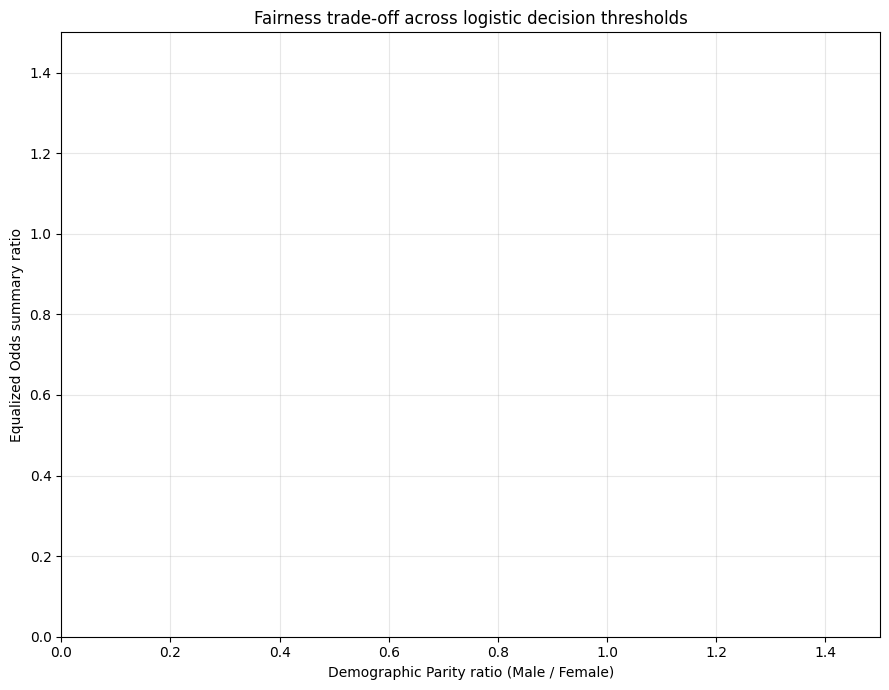

Threshold closest to DP parity:


,threshold,DP_ratio,EO_ratio,PP_ratio,accuracy
0,0.05,2.0814,1.0642,1.3478,0.6345


Threshold closest to EO-summary parity:


,threshold,DP_ratio,EO_ratio,PP_ratio,accuracy
0,0.05,2.0814,1.0642,1.3478,0.6345


In [9]:
def safe_ratio(a, b):
    if pd.isna(a) or pd.isna(b) or abs(b) < 1e-12:
        return np.nan
    return a / b

def group_rates(y_true, y_pred, group_mask):
    yt = np.asarray(y_true)[group_mask]
    yp = np.asarray(y_pred)[group_mask]
    positives = yp == 1
    actual_pos = yt == 1
    actual_neg = yt == 0
    selection = float(np.mean(yp == 1)) if len(yp) else np.nan
    tpr = float(np.sum(positives & actual_pos) / np.sum(actual_pos)) if np.sum(actual_pos) else np.nan
    fpr = float(np.sum(positives & actual_neg) / np.sum(actual_neg)) if np.sum(actual_neg) else np.nan
    precision = float(np.sum(positives & actual_pos) / np.sum(positives)) if np.sum(positives) else np.nan
    return {"selection_rate": selection, "TPR": tpr, "FPR": fpr, "precision": precision}

test_sex = X_test["sex"].astype(str).to_numpy()
y_test_arr = y_test.to_numpy()
thresholds = np.round(np.arange(0.05, 0.951, 0.10), 2)
fair_rows = []
for threshold in thresholds:
    pred = (logit_prob >= threshold).astype(int)
    A = group_rates(y_test_arr, pred, test_sex == "Male")
    B = group_rates(y_test_arr, pred, test_sex == "Female")
    dp = safe_ratio(A["selection_rate"], B["selection_rate"])
    tpr_ratio = safe_ratio(A["TPR"], B["TPR"])
    fpr_ratio = safe_ratio(A["FPR"], B["FPR"])
    eo = min(tpr_ratio, fpr_ratio) if np.isfinite(tpr_ratio) and np.isfinite(fpr_ratio) else np.nan
    pp = safe_ratio(A["precision"], B["precision"])
    fair_rows.append({
        "threshold": threshold, "DP_ratio": dp, "EO_ratio": eo, "PP_ratio": pp,
        "selection_A_male": A["selection_rate"], "selection_B_female": B["selection_rate"],
        "TPR_A_male": A["TPR"], "TPR_B_female": B["TPR"],
        "FPR_A_male": A["FPR"], "FPR_B_female": B["FPR"],
        "precision_A_male": A["precision"], "precision_B_female": B["precision"],
        "accuracy": accuracy_score(y_test_arr, pred)
    })
fairness = pd.DataFrame(fair_rows)
display(fairness.round(4))
fairness.to_csv(OUTPUT_DIR / "fairness_threshold_sweep.csv", index=False)

plt.figure(figsize=(9, 7))
plt.scatter(fairness["DP_ratio"], fairness["EO_ratio"])
for _, r in fairness.iterrows():
    if np.isfinite(r["DP_ratio"]) and np.isfinite(r["EO_ratio"]):
        plt.annotate(f'{r["threshold"]:.2f}', (r["DP_ratio"], r["EO_ratio"]),
                     xytext=(4, 4), textcoords="offset points", fontsize=8)
plt.xlim(0, 1.5)
plt.ylim(0, 1.5)
plt.xlabel("Demographic Parity ratio (Male / Female)")
plt.ylabel("Equalized Odds summary ratio")
plt.title("Fairness trade-off across logistic decision thresholds")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fairness_tradeoff_chart.png", dpi=180, bbox_inches="tight")
plt.show()

# Print best thresholds by closeness to parity, plus a concrete pairwise DP-vs-EO tradeoff.
fairness["DP_distance_from_1"] = (fairness["DP_ratio"] - 1).abs()
fairness["EO_distance_from_1"] = (fairness["EO_ratio"] - 1).abs()
print("Threshold closest to DP parity:")
display(fairness.loc[[fairness["DP_distance_from_1"].idxmin()],
                     ["threshold", "DP_ratio", "EO_ratio", "PP_ratio", "accuracy"]].round(4))
print("Threshold closest to EO-summary parity:")
display(fairness.loc[[fairness["EO_distance_from_1"].idxmin()],
                     ["threshold", "DP_ratio", "EO_ratio", "PP_ratio", "accuracy"]].round(4))

valid = fairness.dropna(subset=["DP_ratio", "EO_ratio"]).copy()
if len(valid) >= 2:
    # Choose the pair with greatest DP improvement and report accompanying EO movement.
    pairs = []
    for i, r1 in valid.iterrows():
        for j, r2 in valid.iterrows():
            if r2["DP_ratio"] < r1["DP_ratio"] and r2["DP_ratio"] <= 1:
                dp_gain = abs(r1["DP_ratio"] - 1) - abs(r2["DP_ratio"] - 1)
                eo_loss = abs(r2["EO_ratio"] - 1) - abs(r1["EO_ratio"] - 1)
                pairs.append((dp_gain, eo_loss, r1, r2))
    if pairs:
        best = max(pairs, key=lambda x: x[0])
        dp_gain, eo_loss, r1, r2 = best
        print(f"Illustrative threshold shift {r1['threshold']:.2f} -> {r2['threshold']:.2f}: "
              f"DP ratio {r1['DP_ratio']:.3f} -> {r2['DP_ratio']:.3f}; "
              f"EO ratio {r1['EO_ratio']:.3f} -> {r2['EO_ratio']:.3f}.")
        print("Use the actual table to explain whether the EO distance from 1 increased or decreased; do not describe a change as a gain unless it moves closer to 1.")


In [10]:
# Export core model summary and coefficient tables.
model_summary = pd.DataFrame([
    {"model": "OLS + median threshold", "threshold": ols_cutoff,
     "accuracy_vs_true": accuracy_score(y_test, ols_class),
     "precision_vs_true": precision_score(y_test, ols_class, zero_division=0),
     "recall_vs_true": recall_score(y_test, ols_class, zero_division=0),
     "f1_vs_true": f1_score(y_test, ols_class, zero_division=0)},
    {"model": "Logistic + 0.50 threshold", "threshold": 0.50,
     "accuracy_vs_true": accuracy_score(y_test, logit_class),
     "precision_vs_true": precision_score(y_test, logit_class, zero_division=0),
     "recall_vs_true": recall_score(y_test, logit_class, zero_division=0),
     "f1_vs_true": f1_score(y_test, logit_class, zero_division=0)}
])
model_summary.to_csv(OUTPUT_DIR / "model_summary.csv", index=False)
display(model_summary.round(4))

# A compact coefficient extract for explaining model behavior.
coef_ci = full_glm.conf_int()
coef_extract = pd.DataFrame({
    "coefficient": full_glm.params,
    "ci_low": coef_ci[0],
    "ci_high": coef_ci[1],
    "p_value": full_glm.pvalues
}).sort_values("p_value")
coef_extract.to_csv(OUTPUT_DIR / "full_model_coefficients.csv", index=True)
print("Most statistically significant terms in explanatory GLM (association, not causation):")
display(coef_extract.head(15).round(5))

print("\nSaved files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print("-", path.name)


,model,threshold,accuracy_vs_true,precision_vs_true,recall_vs_true,f1_vs_true
0,OLS + median threshold,0.2281,0.7088,0.4481,0.9364,0.6061
1,Logistic + 0.50 threshold,0.5000,0.8497,0.7287,0.5921,0.6533


Most statistically significant terms in explanatory GLM (association, not causation):


,coefficient,ci_low,ci_high,p_value
const,-2.25751,-2.32918,-2.18585,0.0
education_num,0.88490,0.85040,0.91941,0.0
capital_gain,2.33720,2.19910,2.47529,0.0
age,0.55000,0.51731,0.58269,0.0
sex_Male,1.20576,1.12869,1.28283,0.0
hours_per_week,0.42295,0.39100,0.45490,0.0
capital_loss,0.26854,0.24291,0.29417,0.0



Saved files:
- adversarial_subset.csv
- adversarial_trait_summary.csv
- fairness_threshold_sweep.csv
- fairness_tradeoff_chart.png
- full_model_coefficients.csv
- model_summary.csv
- numeric_boxplots.png
- omitted_variable_bias.csv
- part1_test_predictions.csv
- subgroup_coefficients.csv
